# **13.  Clasificadores de soporte vectorial.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.svm import SVC

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [2]:
def graficar_svm_lineal(
    modelo,
    X,
    y,
    titulo="Clasificador de soporte vectorial"
):
    
    plt.figure(figsize=(8, 6))
    
    for clase in np.unique(y):
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=70
        )
    
    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1
    
    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1
    
    xx = np.linspace(x_min, x_max, 300)
    yy = np.linspace(y_min, y_max, 300)
    
    YY, XX = np.meshgrid(yy, xx)
    
    grid = np.c_[XX.ravel(), YY.ravel()]
    
    Z = modelo.decision_function(grid)
    Z = Z.reshape(XX.shape)
    
    plt.contour(
        XX,
        YY,
        Z,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"]
    )
    
    plt.scatter(
        modelo.support_vectors_[:, 0],
        modelo.support_vectors_[:, 1],
        s=180,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Vectores de soporte"
    )
    
    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()

## 13.3 Datos con traslape.

In [3]:
X, y = make_blobs(n_samples=120, centers = [[-1.5, -1.0],[1.5,1.0]], cluster_std=1.25, random_state=42)

In [4]:
y = np.where(y==0, -1, 1)
y

array([-1, -1,  1, -1, -1, -1, -1, -1,  1,  1,  1, -1,  1,  1,  1,  1, -1,
       -1, -1, -1, -1, -1, -1, -1,  1, -1,  1,  1,  1,  1, -1, -1, -1, -1,
        1, -1,  1, -1,  1, -1,  1, -1,  1,  1,  1, -1, -1,  1, -1,  1, -1,
       -1,  1,  1,  1, -1, -1,  1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1,
        1,  1, -1,  1, -1,  1,  1, -1,  1, -1, -1,  1,  1,  1,  1,  1, -1,
        1,  1, -1, -1,  1, -1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1, -1,
        1,  1, -1,  1, -1,  1,  1, -1, -1, -1, -1,  1,  1,  1,  1, -1, -1,
        1])

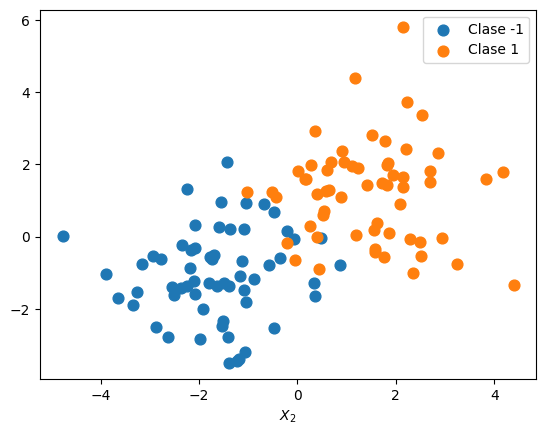

In [5]:
plt.Figure(figsize=(8,6))

for clase in np.unique(y):
    plt.scatter(X[y==clase, 0], X[y==clase, 1], label = f"Clase {clase}", s=60)

plt.xlabel("$X_1$")
plt.xlabel("$X_2$")
plt.legend()
plt.show()

## 13.6 Primer clasificador de margen suave

In [6]:
modelo_C1 = SVC(kernel = "linear", C = 1)

modelo_C1.fit(X,y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


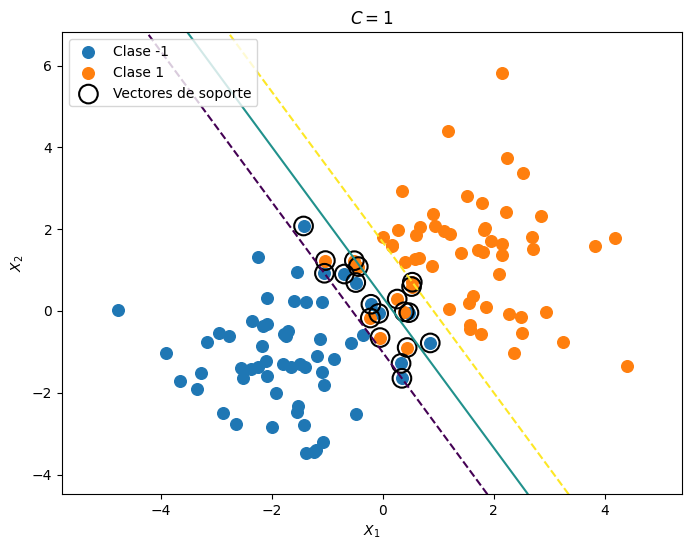

In [7]:
graficar_svm_lineal(modelo_C1, X, y, titulo="$C=1$")

## 13.7 Identificando la posición de las observaciones.

In [8]:
decision = modelo_C1.decision_function(X)
margen_funcional = y * decision

In [9]:
resultados = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:, 1],
    "Clase": y,
    "Decision": decision,
    "y_f(x)": margen_funcional
})

resultados.head(10)

,X1,X2,Clase,Decision,y_f(x)
0,-1.701607,-0.494936,-1,-2.944531,2.944531
1,-1.774590,-0.553609,-1,-3.087797,3.087797
2,0.441508,-0.893559,1,-0.311709,-0.311709
3,-1.543390,-2.460848,-1,-4.186999,4.186999
4,-1.048255,0.922546,-1,-0.999970,0.999970
5,-2.079272,-1.582162,-1,-4.267318,4.267318
6,-2.250798,-1.364617,-1,-4.340296,4.340296
7,-1.085921,0.219431,-1,-1.573139,1.573139
8,1.767617,-0.557173,1,1.750028,1.750028
9,1.193265,0.057830,1,1.421491,1.421491


In [10]:
def posicion_margen(valor):
    if valor <0:
        return "Mal clasificada"
    elif valor <1:
        return "Dentro del margen"
    else:
        return "Sobre o fuera del margen"

In [11]:
resultados["Posicion"] = (
    resultados["y_f(x)"].apply(posicion_margen)
)
resultados.head(10)

,X1,X2,Clase,Decision,y_f(x),Posicion
0,-1.701607,-0.494936,-1,-2.944531,2.944531,Sobre o fuera del margen
1,-1.774590,-0.553609,-1,-3.087797,3.087797,Sobre o fuera del margen
2,0.441508,-0.893559,1,-0.311709,-0.311709,Mal clasificada
3,-1.543390,-2.460848,-1,-4.186999,4.186999,Sobre o fuera del margen
4,-1.048255,0.922546,-1,-0.999970,0.999970,Dentro del margen
5,-2.079272,-1.582162,-1,-4.267318,4.267318,Sobre o fuera del margen
6,-2.250798,-1.364617,-1,-4.340296,4.340296,Sobre o fuera del margen
7,-1.085921,0.219431,-1,-1.573139,1.573139,Sobre o fuera del margen
8,1.767617,-0.557173,1,1.750028,1.750028,Sobre o fuera del margen
9,1.193265,0.057830,1,1.421491,1.421491,Sobre o fuera del margen


In [12]:
resultados.groupby(["Posicion"]).count()

,X1,X2,Clase,Decision,y_f(x)
Posicion,,,,,
Dentro del margen,11,11,11,11,11
Mal clasificada,8,8,8,8,8
Sobre o fuera del margen,101,101,101,101,101


## 13.8 ¿Qué ocurre cuando cambiamos C?

In [13]:
valores_C = [0.01, 0.1, 1, 10, 100]

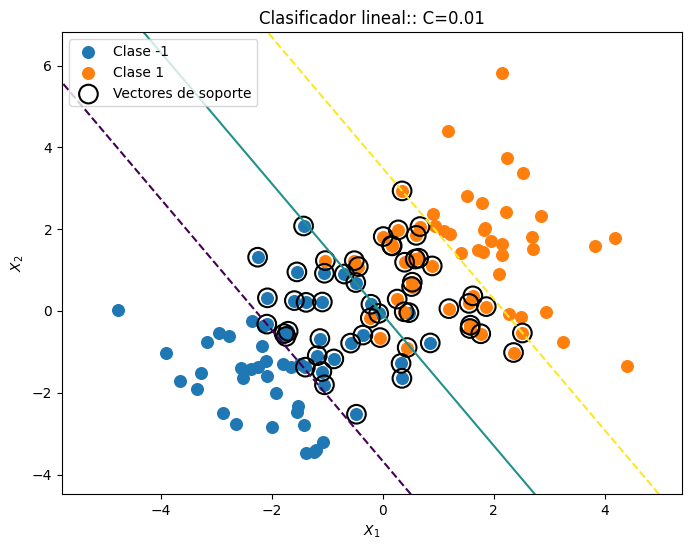

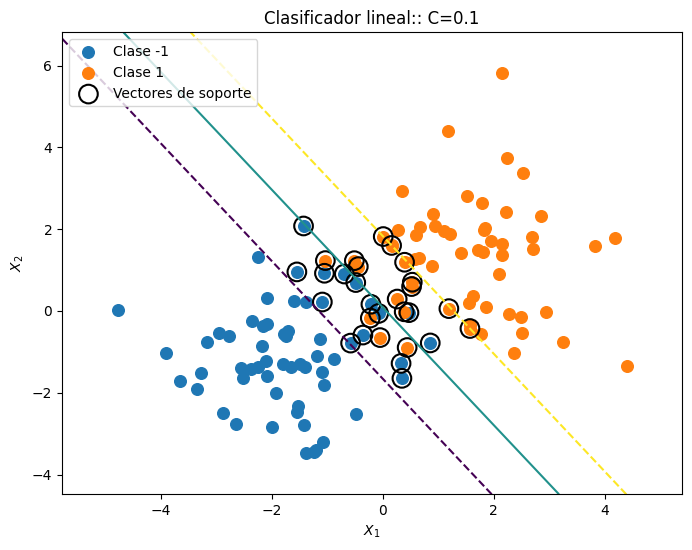

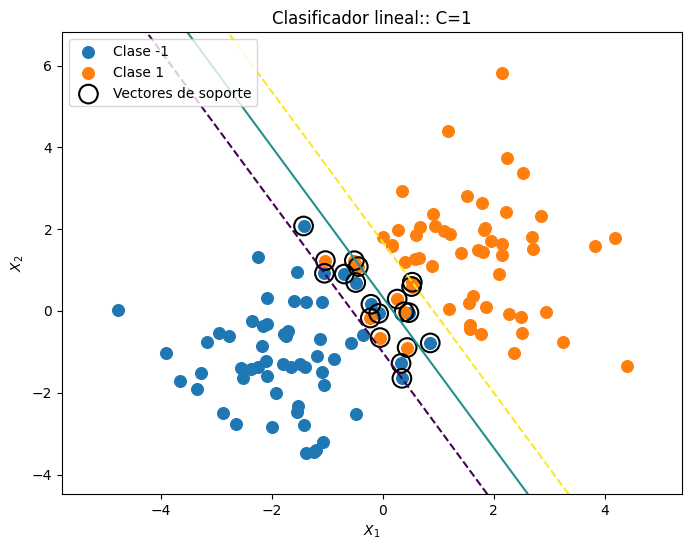

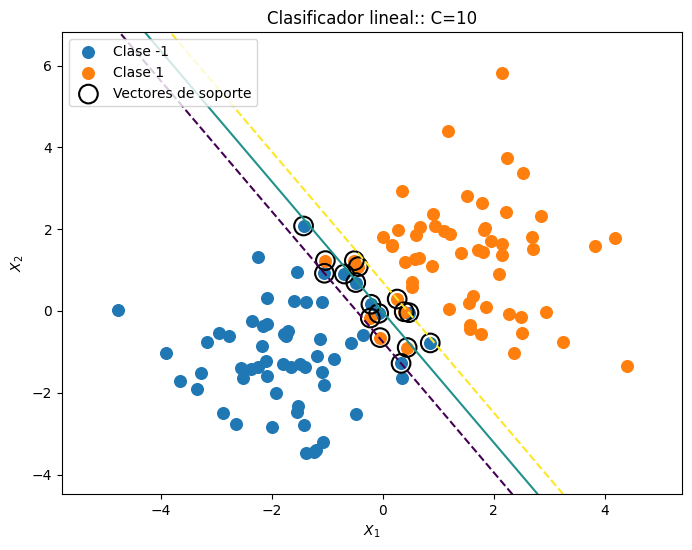

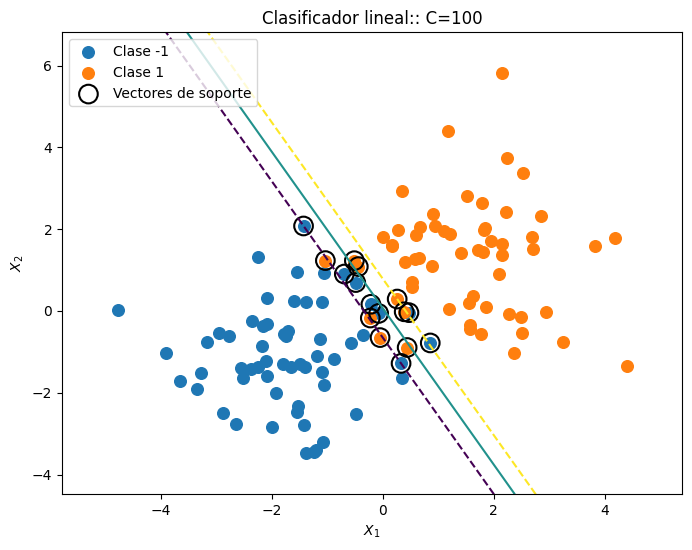

In [14]:
for C in valores_C:
    modelo = SVC(kernel="linear", C=C)
    modelo.fit(X,y)
    graficar_svm_lineal(modelo, X, y, titulo=f"Clasificador lineal:: C={C}")

## 13.9 Construyamos una tabla comparativa.

In [15]:


acuracy = accuracy_score(y, modelo_C1.predict(X))
no_vectores = sum(modelo_C1.n_support_)
no_obs_dentro = (resultados['Posicion'] == "Sobre o fuera del margen").sum()

In [16]:
tabla = []

for C in valores_C:
    modelo = SVC(kernel="linear", C=C)
    modelo.fit(X,y)

    accuracy = accuracy_score(y, modelo.predict(X))
    no_vectores = sum(modelo.n_support_)

    decision = modelo.decision_function(X)
    margen_funcional = y * decision

    resultados = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:, 1],
    "Clase": y,
    "Decision": decision,
    "y_f(x)": margen_funcional
    })

    resultados["Posicion"] = (
    resultados["y_f(x)"].apply(posicion_margen))

    no_obs_dentro = (resultados['Posicion'] == "Dentro del margen").sum()

    tabla.append({
            "C": C,
            "Accuracy": accuracy,
            "No. de vectores soporte": no_vectores,
            "Dentro del margen": no_obs_dentro
        })

df_tabla = pd.DataFrame(tabla)
df_tabla

,C,Accuracy,No. de vectores soporte,Dentro del margen
0,0.01,0.941667,59,51
1,0.10,0.950000,29,21
2,1.00,0.933333,20,11
3,10.00,0.950000,17,10
4,100.00,0.950000,16,9


## 13.10 Entrenamiento no es generalización.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)

In [18]:
tabla = []

for C in valores_C:
    modelo = SVC(kernel="linear", C=C)
    modelo.fit(X_train,y_train)

    accuracy_train = accuracy_score(y_train, modelo.predict(X_train))
    no_vectores = sum(modelo.n_support_)

    decision = modelo.decision_function(X)
    margen_funcional = y * decision

    resultados = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:, 1],
    "Clase": y,
    "Decision": decision,
    "y_f(x)": margen_funcional
    })

    resultados["Posicion"] = (
    resultados["y_f(x)"].apply(posicion_margen))

    no_obs_dentro = (resultados['Posicion'] == "Dentro del margen").sum()

    pred_test = modelo.predict(X_test)

    accuracy_test = accuracy_score(y_test, modelo.predict(X_test))

    tabla.append({
            "C": C,
            "Accuracy_train": accuracy_train,
            "Accuracy_test": accuracy_test,
            "No. de vectores soporte": no_vectores,
            "Dentro del margen": no_obs_dentro
        })

df_tabla = pd.DataFrame(tabla)
df_tabla

,C,Accuracy_train,Accuracy_test,No. de vectores soporte,Dentro del margen
0,0.01,0.940476,0.833333,46,52
1,0.10,0.964286,0.888889,20,25
2,1.00,0.952381,0.888889,11,10
3,10.00,0.964286,0.888889,9,7
4,100.00,0.964286,0.888889,8,6


## 13.11 SVM y escala de las variables.

In [19]:
X_desescalado = X.copy()

X_desescalado[:,1] = (1000*X_desescalado[:,1])
X_desescalado

array([[-1.70160714e+00, -4.94936429e+02],
       [-1.77458986e+00, -5.53609286e+02],
       [ 4.41507852e-01, -8.93559031e+02],
       [-1.54338971e+00, -2.46084755e+03],
       [-1.04825549e+00,  9.22545708e+02],
       [-2.07927212e+00, -1.58216219e+03],
       [-2.25079836e+00, -1.36461719e+03],
       [-1.08592071e+00,  2.19431409e+02],
       [ 1.76761718e+00, -5.57173473e+02],
       [ 1.19326485e+00,  5.78297946e+01],
       [ 3.95178205e-01,  1.19215638e+03],
       [-2.93874197e+00, -5.30377477e+02],
       [ 1.08706285e-02,  1.82069201e+03],
       [ 1.57276090e+00, -4.28712872e+02],
       [-4.61883886e-02, -6.50570766e+02],
       [ 5.87041710e-01,  1.27057324e+03],
       [-2.08684298e+00, -3.21799946e+02],
       [-1.37865306e+00,  2.10806238e+02],
       [-7.14714819e-02, -6.00837091e+01],
       [-1.07047714e+00, -3.20380019e+03],
       [ 3.32060961e-01, -1.28222038e+03],
       [ 3.47367556e-01, -1.64783777e+03],
       [-4.71818860e-01, -2.52605456e+03],
       [-5.

In [20]:
pd.DataFrame(X_desescalado, columns=["X1", "X2"]).describe()

,X1,X2
count,120.000000,120.000000
mean,-0.102725,96.718547
std,1.918775,1724.595599
min,-4.774681,-3484.461143
25%,-1.556090,-1187.641213
50%,-0.058830,-33.279743
75%,1.560914,1428.095042
max,4.393323,5815.914363


## 13.12 Ajuste sin escalamiento.

In [21]:
modelo_sin_escalar = SVC(kernel = "linear", C=1)
modelo_sin_escalar.fit(X_desescalado, y)
modelo_sin_escalar.coef_

array([[1.53345981e+00, 1.00536765e-03]])

## 13.13 Estandarización.

In [22]:
scaler = StandardScaler()

X_escalado = scaler.fit_transform(X_desescalado)

pd.DataFrame(X_escalado, columns = ["X_1", "X_2"]).describe()

,X_1,X_2
count,1.200000e+02,1.200000e+02
mean,-2.220446e-17,1.850372e-17
std,1.004193e+00,1.004193e+00
min,-2.445074e+00,-2.085240e+00
25%,-7.606205e-01,-7.478535e-01
50%,2.297229e-02,-7.569505e-02
75%,8.706670e-01,7.752303e-01
max,2.353012e+00,3.330158e+00


## 13.14 Ajuste después del escalamiento.

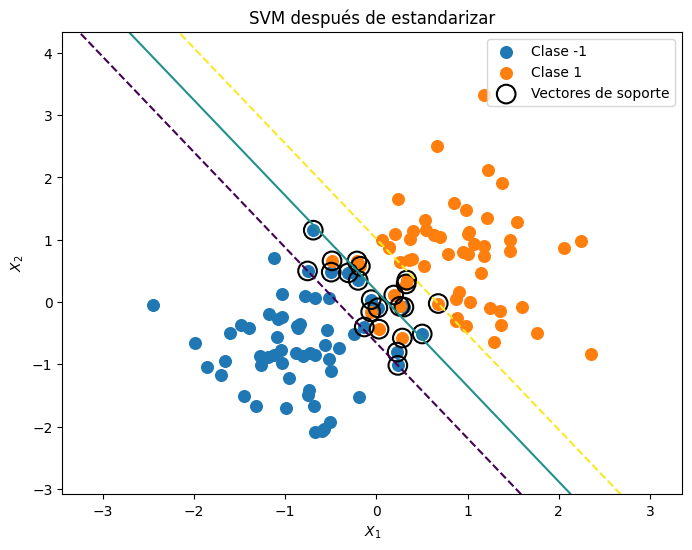

In [23]:
modelo_escalado = SVC(kernel = "linear", C = 1)
modelo_escalado.fit(X_escalado, y)

graficar_svm_lineal(modelo_escalado, X_escalado, y, titulo = "SVM después de estandarizar")

## 13.16 Forma correcta con entrenamiento y prueba.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X_desescalado, y, test_size=0.30, random_state=42, stratify=y)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

## 13.17 Pipeline: una forma más segura.

In [25]:
modelo_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "linear", C=1))
    ]
)

modelo_pipeline.fit(X_train, y_train)

pred_train = modelo_pipeline.predict(X_train)
pred_test = modelo_pipeline.predict(X_test)

In [26]:
accuracy_score(y_train, pred_train)

0.9642857142857143

In [27]:
accuracy_score(y_test, pred_test)

0.8888888888888888

## Ejercicios

**13.19.1 Ejercicio 1. Observaciones y margen.** Utilizando modelo_C1, calcula

$$
y_i f(x_i)
$$

para todas las observaciones.

Encuentra:

1) cuántas están mal clasificadas;
2) cuántas están correctamente clasificadas pero dentro del margen;
3) cuántas están sobre o fuera del margen.

In [28]:
X1, y1 = make_blobs(
    n_samples=120,
    centers=[
        [-2.7, -2.5],
        [2.5, 2.7]
    ],
    cluster_std=2.0,
    random_state=42
)

In [29]:
y1 = np.where(y1 == 0, -1, 1)

In [30]:
modelo1 = SVC(kernel = "linear", C = 1)

modelo1.fit(X1,y1)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [31]:
decision1 = modelo1.decision_function(X1)
margen_funcional1 = y1 * decision1

resultados1 = pd.DataFrame({
    "X1": X1[:, 0],
    "X2": X1[:, 1],
    "Clase": y1,
    "Decision": decision1,
    "y_f(x)": margen_funcional1
})

resultados1["Posicion"] = (
    resultados1["y_f(x)"]
    .apply(posicion_margen)
)


In [32]:
resultados1["Posicion"].value_counts()

Posicion
Sobre o fuera del margen    115
Dentro del margen             5
Name: count, dtype: int64

**13.19.2 Ejercicio 2. Efecto de un valor extremo de $C$.** Ajusta dos modelos:

$$
C = 0.001
$$

y

$$
C = 1000
$$

Compara:

- frontera;
- margen;
- número de vectores de soporte;
- exactitud de entrenamiento.

No selecciones un modelo únicamente a partir de estas cantidades. El objetivo es interpretar cómo cambia el ajuste.

In [33]:
valores_C1 = [
    0.001,
    1000
]

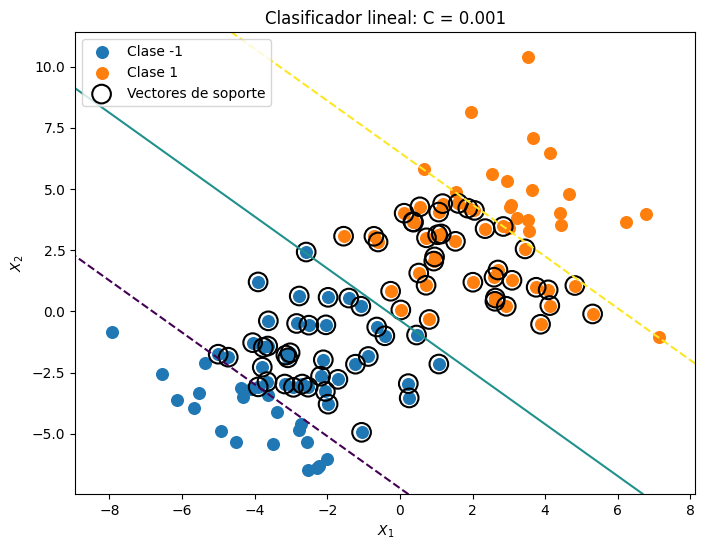

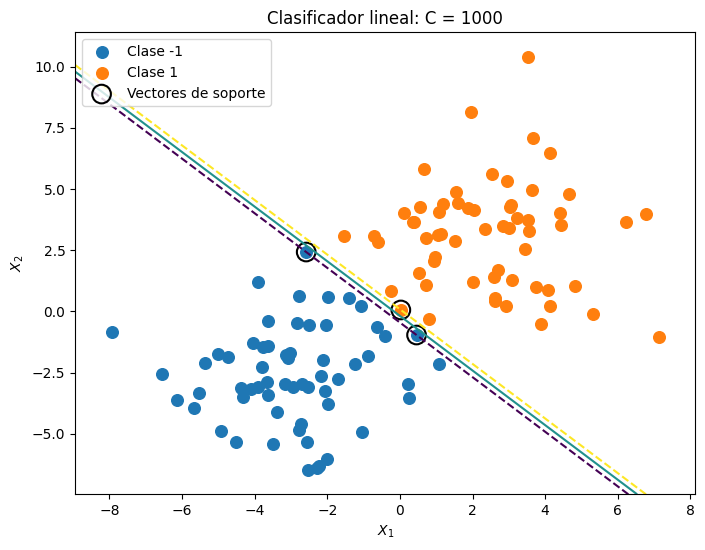

In [34]:
for C in valores_C1:
    
    modelo = SVC(
        kernel="linear",
        C=C
    )
    
    modelo.fit(X1, y1)
    
    graficar_svm_lineal(
        modelo,
        X1,
        y1,
        titulo=f"Clasificador lineal: C = {C}"
    )

In [35]:
comparacion = []

for C in valores_C1:
    
    modelo = SVC(
        kernel="linear",
        C=C
    )
    
    modelo.fit(X1, y1)
    
    pred = modelo.predict(X1)
    decision = modelo.decision_function(X1)
    
    y_f = y1 * decision
    
    comparacion.append({
        "C": C,
        "Accuracy": accuracy_score(y1, pred),
        "Vectores_soporte": len(modelo.support_),
        "Dentro_o_violan_margen": np.sum(y_f < 1)
    })

comparacion = pd.DataFrame(comparacion)

comparacion

,C,Accuracy,Vectores_soporte,Dentro_o_violan_margen
0,0.001,0.991667,78,77
1,1000.000,1.000000,3,2


**13.19.3 Ejercicio 3. Cambiar artificialmente la escala.** A partir de X, crea un nuevo conjunto donde

$$
X_{1}^{*} = 100X_{1}
$$

mientras que $X_2$ permanece sin cambios.

Ajusta:

1) una SVM sin escalamiento;
2) una SVM dentro de un Pipeline con StandardScaler.

Compara los resultados.



In [51]:
X_desescalado3 = X1.copy()

X_desescalado3[:, 0] = 100 * X_desescalado3[:, 0]

In [52]:
modelo_sin_escalar3 = SVC(
    kernel="linear",
    C=1
)

modelo_sin_escalar3.fit(
    X_desescalado3,
    y1
)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [53]:
modelo_pipeline3 = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="linear",
            C=1
        )
    )
])

In [54]:
modelo_pipeline3.fit(
    X_desescalado3,
    y1
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [56]:
df_datos = pd.DataFrame({
    "Modelo": [
        "SVM sin escalar",
        "SVM con pipeline"
    ],
    "Intercepto": [
        modelo_sin_escalar3.intercept_[0],
        modelo_pipeline3.named_steps['svc'].intercept_[0]
    ],
    "Primer coeficiente": [
        modelo_sin_escalar3.coef_[0][0],
        modelo_pipeline3.named_steps['svc'].coef_[0][0]
    ],
    "Segundo coeficiente": [
        modelo_sin_escalar3.coef_[0][1],
        modelo_pipeline3.named_steps['svc'].coef_[0][1]
    ]
})

df_datos

,Modelo,Intercepto,Primer coeficiente,Segundo coeficiente
0,SVM sin escalar,0.230488,0.019117,1.525138
1,SVM con pipeline,-0.298256,1.665279,1.991744
